In [2]:
!pip install ultralytics

import ultralytics

print("Ultralytics Version:", ultralytics.__version__)

ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [3]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

CUDA Available: True
GPU: Tesla T4


In [5]:
import zipfile
import os

# Pointing directly to the zip file already available in the environment
zip_file = "/content/Fruit-detector2.v5i.yolov8.zip"

extract_path = "/content/fruit_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files_list[:5]:
            print("  " * (level + 1) + file)

fruit_dataset/
  README.roboflow.txt
  README.dataset.txt
  data.yaml
  test/
    labels/
      -00048_jpeg_jpg.rf.828dad352687826e2adc4c0cfd44e93a.txt
      b_f516_png.rf.dcfa33636d37367df3b4fea9702e0b59.txt
      b_f116_png.rf.688a776ca964b13ffeadaaeef5f5c1e4.txt
      -00126_jpeg_jpg.rf.8f7b0bb0fa41652c4d8fa9433f0e6afb.txt
      -00051_jpeg_jpg.rf.491ee2173a42d894b304c2e511ccd1a4.txt
    images/
      b_f116_png.rf.688a776ca964b13ffeadaaeef5f5c1e4.jpg
      Alpukat-Bagus-109-_jpg.rf.bf34981d56def7a52782894d87e2600b.jpg
      000006_jpg.rf.c96f347eb8b9ffecc9e9587b9168a1c0.jpg
      100049_jpg.rf.c483017161fa4b7dca599d424e2358fa.jpg
      sour_85_jpg.rf.de276272b5b47a3faaee4dc9ef4b9f7f.jpg
  train/
    labels/
      rotated_by_15_Screen-Shot-2018-06-12-at-9-52-58-PM_png.rf.11f1f57a5ee29b955ec1d651840ac589.txt
      freshMango-56-_jpg.rf.90c0752864f96fe2a4bfa2f736b0ecef.txt
      Fresh-12_jpg.rf.586e5f665eb240ef1a3ab0943c5f9819.txt
      Alpukat-Bagus-63-_jpg.rf.65d687b28d033a17ff2e32d

In [7]:
import glob

yaml_files = glob.glob(
    os.path.join(extract_path, "**", "data.yaml"),
    recursive=True
)

print(yaml_files)

['/content/fruit_dataset/data.yaml']


In [8]:
yaml_path = yaml_files[0]

print("YAML file:", yaml_path)

YAML file: /content/fruit_dataset/data.yaml


In [9]:
import yaml

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print(data_config)

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 5, 'names': ['Apple', 'Avocado', 'Banana', 'Mango', 'Orange'], 'roboflow': {'workspace': 'grik-project', 'project': 'fruit-detector2', 'version': 5, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/grik-project/fruit-detector2/dataset/5'}}


In [10]:
dataset_path = os.path.dirname(yaml_path)

data_config["path"] = dataset_path
data_config["train"] = "train/images"
data_config["val"] = "valid/images"

if os.path.exists(os.path.join(dataset_path, "test", "images")):
    data_config["test"] = "test/images"

with open(yaml_path, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("Dataset paths configured successfully!")

Dataset paths configured successfully!


In [11]:
print("Classes:", data_config["names"])
print("Number of classes:", data_config["nc"])

print(
    "Training images:",
    len(glob.glob(os.path.join(dataset_path, "train", "images", "*")))
)

print(
    "Validation images:",
    len(glob.glob(os.path.join(dataset_path, "valid", "images", "*")))
)

Classes: ['Apple', 'Avocado', 'Banana', 'Mango', 'Orange']
Number of classes: 5
Training images: 425
Validation images: 50


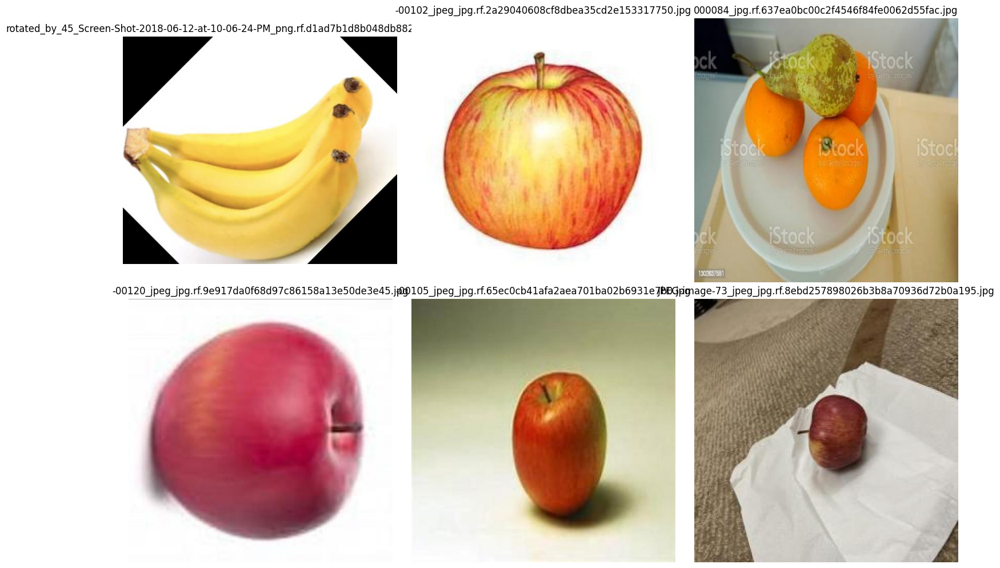

In [12]:
import glob
import random
import matplotlib.pyplot as plt
from PIL import Image

image_paths = glob.glob(
    os.path.join(dataset_path, "train", "images", "*")
)

sample_images = random.sample(
    image_paths,
    min(6, len(image_paths))
)

plt.figure(figsize=(15, 10))

for i, image_path in enumerate(sample_images):
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(os.path.basename(image_path))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
label_paths = glob.glob(
    os.path.join(dataset_path, "train", "labels", "*.txt")
)

print("Total annotation files:", len(label_paths))

with open(label_paths[0], "r") as file:
    print("Sample annotation:")
    print(file.read())

Total annotation files: 425
Sample annotation:
2 0.5021363636363636 0.49542168674698783 0.9527727272727273 0.8061144578313253


In [14]:
!pip install ultralytics

In [15]:
from ultralytics import YOLO
import torch

print("GPU Available:", torch.cuda.is_available())

model = YOLO("yolov8n.pt")

print("YOLOv8 Nano loaded successfully!")

GPU Available: True
YOLOv8 Nano loaded successfully!


In [16]:
results = model.train(
    data=yaml_path,
    epochs=20,
    imgsz=640,
    batch=16,
    device=0 if torch.cuda.is_available() else "cpu",
    patience=0,
    project="/content/runs/detect",
    name="fruit_detection",
    plots=True,
    save=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fruit_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fruit_detection, nbs=64, nms=None, opset=None, optimize

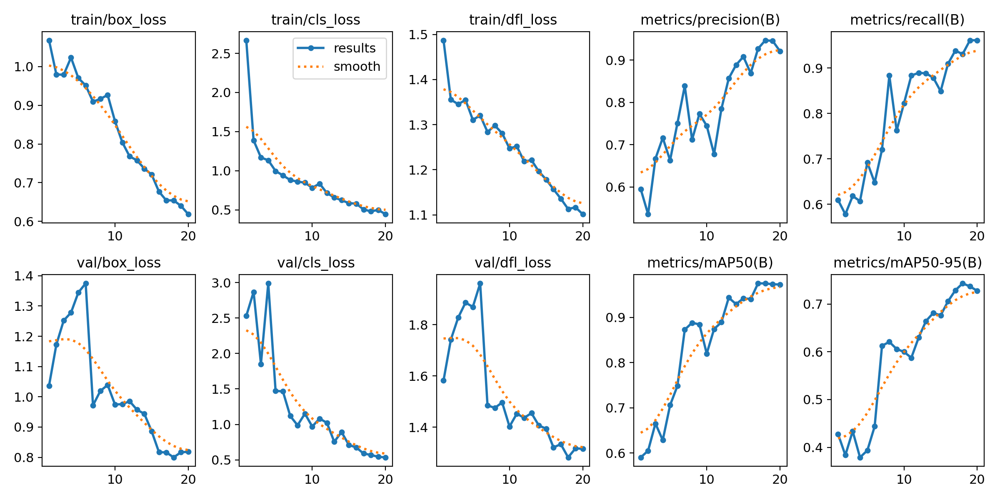

In [17]:
from IPython.display import Image, display

results_path = "/content/runs/detect/fruit_detection"

display(Image(filename=f"{results_path}/results.png"))

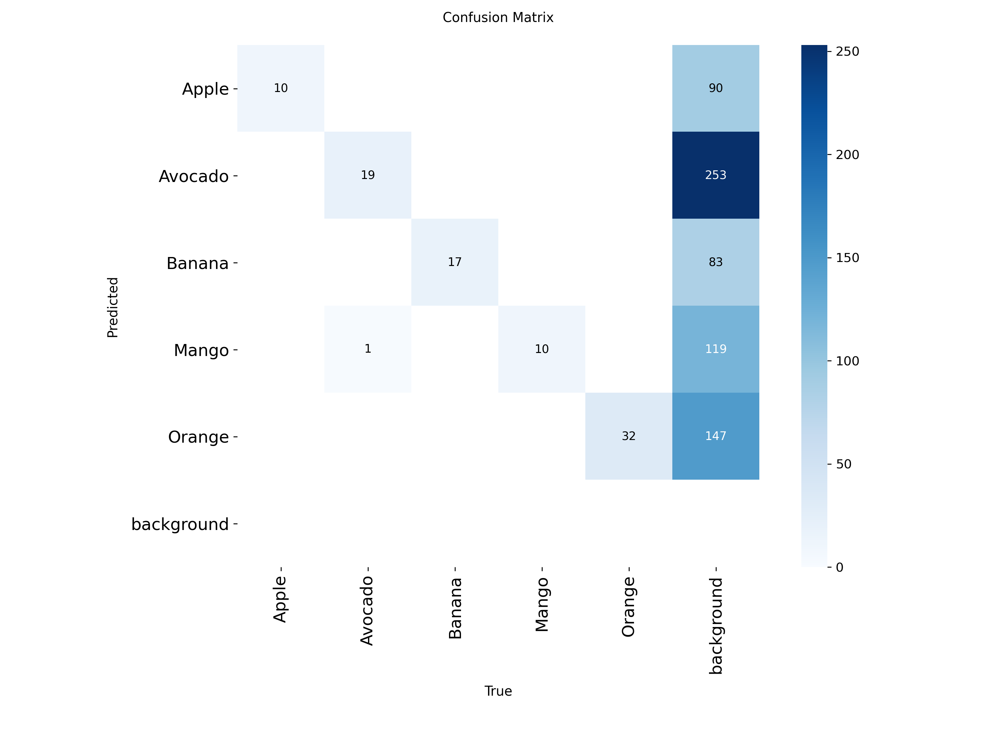

In [18]:
display(
    Image(filename=f"{results_path}/confusion_matrix.png")
)

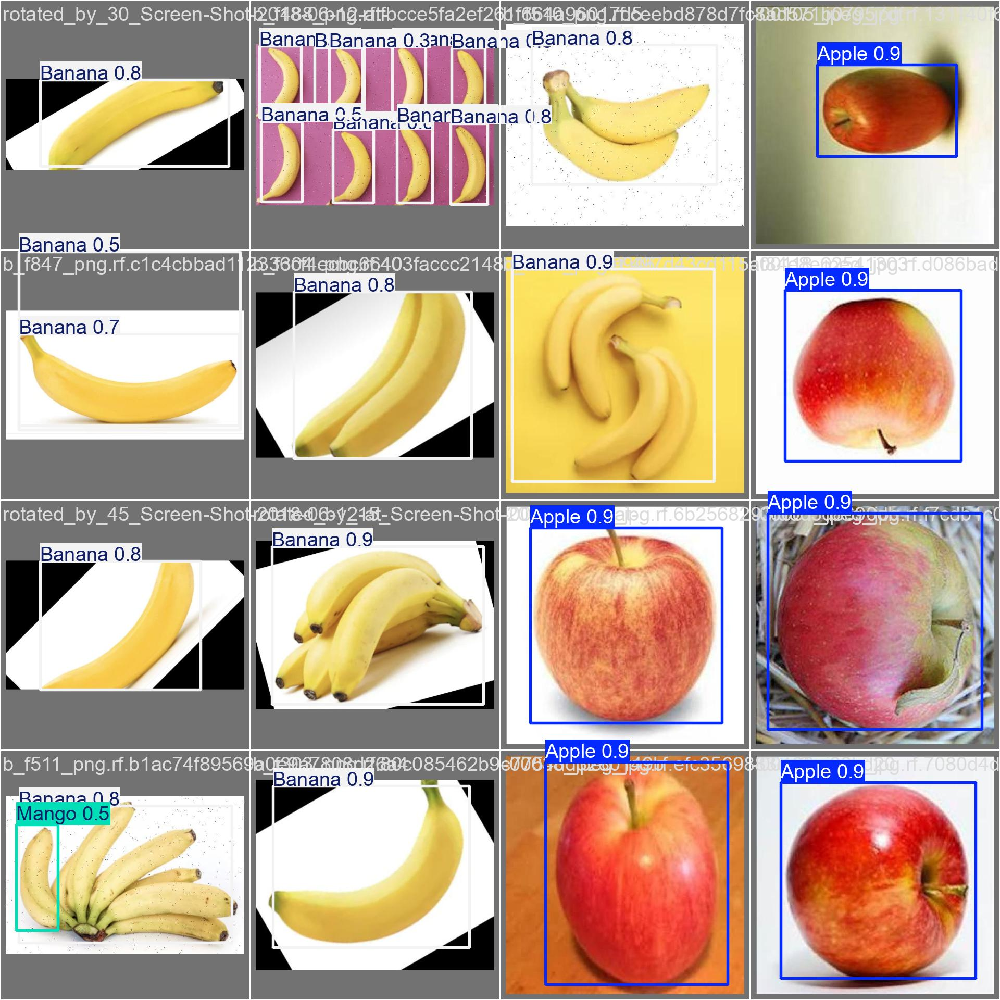

In [19]:
display(
    Image(filename=f"{results_path}/val_batch0_pred.jpg")
)

Saving images.jpeg to images.jpeg

image 1/1 /content/images.jpeg: 448x640 5 Oranges, 36.3ms
Speed: 1.7ms preprocess, 36.3ms inference, 14.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


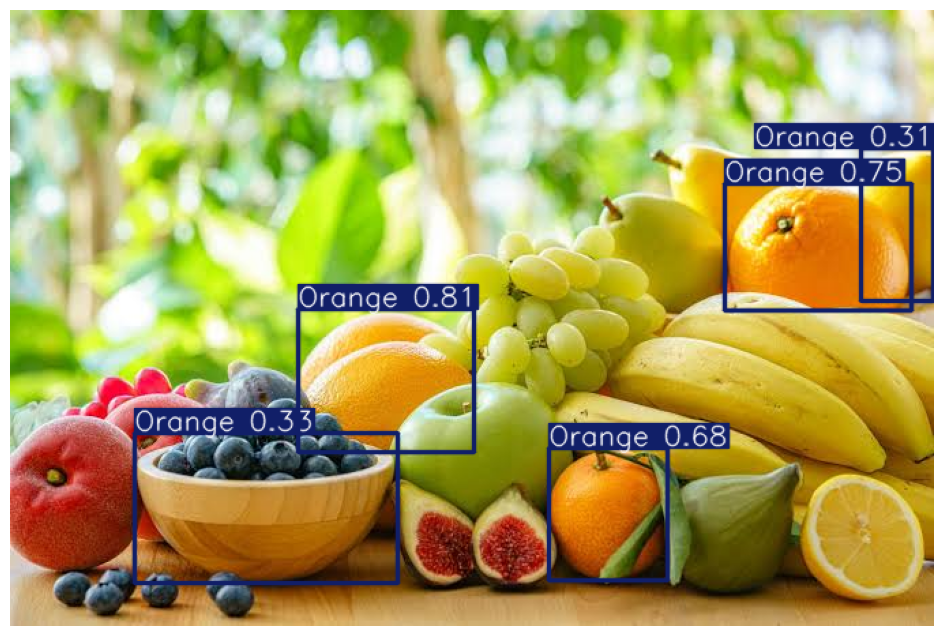

In [20]:
from ultralytics import YOLO
from google.colab import files
import matplotlib.pyplot as plt

best_model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

uploaded = files.upload()

test_image = list(uploaded.keys())[0]

results = best_model.predict(
    source=test_image,
    conf=0.25,
    save=True
)

annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.show()

Saving banana.jpeg to banana.jpeg

image 1/1 /content/banana.jpeg: 448x640 1 Banana, 6.3ms
Speed: 1.8ms preprocess, 6.3ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-2


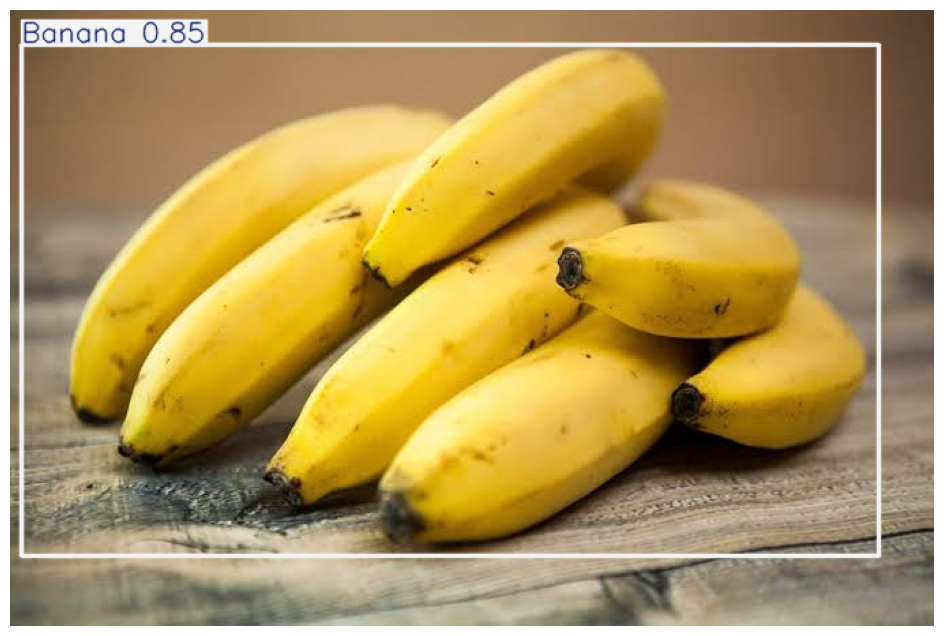

In [22]:
from ultralytics import YOLO
from google.colab import files
import matplotlib.pyplot as plt

best_model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

uploaded = files.upload()

test_image = list(uploaded.keys())[0]

results = best_model.predict(
    source=test_image,
    conf=0.25,
    save=True
)

annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.show()

Saving apples-1296x728-header.webp to apples-1296x728-header.webp

image 1/1 /content/apples-1296x728-header.webp: 384x640 2 Mangos, 6.8ms
Speed: 1.8ms preprocess, 6.8ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict-3


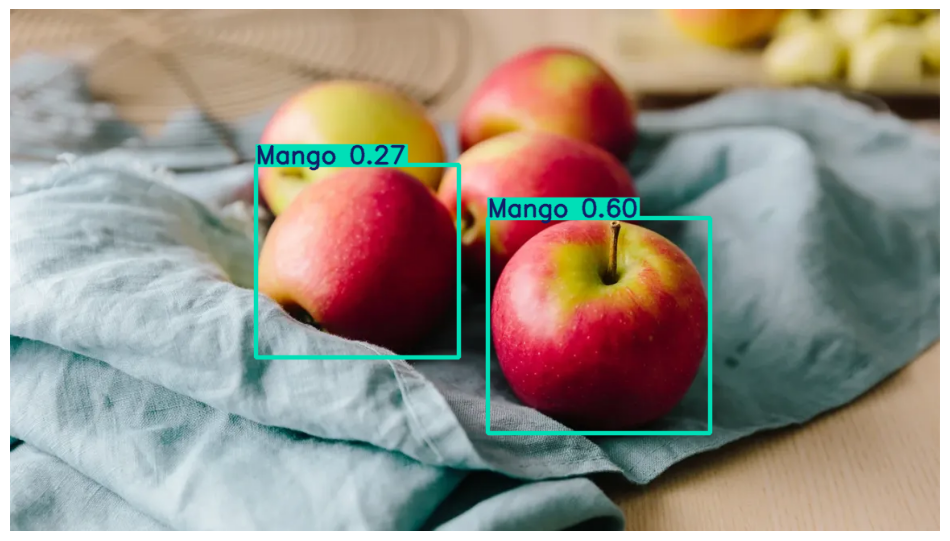

In [23]:
from ultralytics import YOLO
from google.colab import files
import matplotlib.pyplot as plt

best_model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

uploaded = files.upload()

test_image = list(uploaded.keys())[0]

results = best_model.predict(
    source=test_image,
    conf=0.25,
    save=True
)

annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.show()

In [24]:
print("Model class mapping:")
print(best_model.names)

print("\nDataset class mapping:")
print(data_config["names"])

Model class mapping:
{0: 'Apple', 1: 'Avocado', 2: 'Banana', 3: 'Mango', 4: 'Orange'}

Dataset class mapping:
['Apple', 'Avocado', 'Banana', 'Mango', 'Orange']


In [25]:
from collections import Counter
import glob
import os

label_files = glob.glob(
    os.path.join(dataset_path, "train", "labels", "*.txt")
)

class_counts = Counter()

for file in label_files:
    with open(file, "r") as f:
        for line in f:
            values = line.strip().split()
            if values:
                class_id = int(values[0])
                class_counts[class_id] += 1

print("Training annotation distribution:")

for class_id, count in sorted(class_counts.items()):
    print(f"{class_id} - {data_config['names'][class_id]}: {count}")

Training annotation distribution:
0 - Apple: 86
1 - Avocado: 179
2 - Banana: 97
3 - Mango: 128
4 - Orange: 233


In [27]:
from collections import Counter
import glob
import os

for split in ["train", "valid"]:
    label_files = glob.glob(
        os.path.join(dataset_path, split, "labels", "*.txt")
    )

    counts = Counter()

    for file in label_files:
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()
                if values:
                    counts[int(values[0])] += 1

    print(f"\n{split.upper()} DISTRIBUTION")

    for class_id, name in enumerate(data_config["names"]):
        print(f"{name}: {counts[class_id]}")


TRAIN DISTRIBUTION
Apple: 86
Avocado: 179
Banana: 97
Mango: 128
Orange: 233

VALID DISTRIBUTION
Apple: 10
Avocado: 20
Banana: 17
Mango: 10
Orange: 32


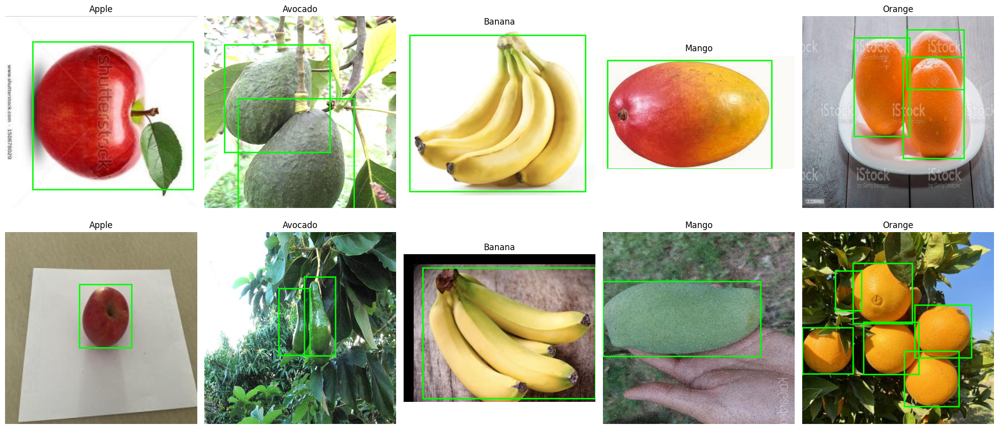

In [28]:
import os
import glob
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

class_names = data_config["names"]

image_dir = os.path.join(dataset_path, "train", "images")
label_dir = os.path.join(dataset_path, "train", "labels")

image_files = (
    glob.glob(os.path.join(image_dir, "*.jpg")) +
    glob.glob(os.path.join(image_dir, "*.jpeg")) +
    glob.glob(os.path.join(image_dir, "*.png"))
)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for class_id, class_name in enumerate(class_names):

    matching_files = []

    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):
        with open(label_file, "r") as f:
            lines = f.readlines()

        if any(
            line.strip() and int(line.split()[0]) == class_id
            for line in lines
        ):
            matching_files.append(label_file)

    selected = random.sample(
        matching_files,
        min(2, len(matching_files))
    )

    for row in range(2):

        ax = axes[row, class_id]
        ax.axis("off")

        if row >= len(selected):
            continue

        label_file = selected[row]
        image_name = os.path.splitext(
            os.path.basename(label_file)
        )[0]

        possible_images = [
            os.path.join(image_dir, image_name + ext)
            for ext in [".jpg", ".jpeg", ".png"]
        ]

        image_path = next(
            (p for p in possible_images if os.path.exists(p)),
            None
        )

        if image_path is None:
            continue

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        ax.imshow(image)

        with open(label_file, "r") as f:
            for line in f:
                values = line.split()

                if not values:
                    continue

                cls, x, y, w, h = map(float, values)

                x1 = (x - w / 2) * width
                y1 = (y - h / 2) * height

                rect = patches.Rectangle(
                    (x1, y1),
                    w * width,
                    h * height,
                    linewidth=2,
                    edgecolor="lime",
                    facecolor="none"
                )

                ax.add_patch(rect)
                ax.set_title(class_names[int(cls)])

plt.tight_layout()
plt.show()

In [29]:
from ultralytics import YOLO
from IPython.display import Image, display

best_model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

metrics = best_model.val(
    data=yaml_path,
    plots=True,
    conf=0.25
)

print("Validation results:")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("Validation output directory:")
print(metrics.save_dir)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1384.7±760.9 MB/s, size: 47.2 KB)
val: Scanning /content/fruit_dataset/valid/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 10.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5it/s 1.6s
                   all         50         89      0.963      0.934      0.958      0.728
                 Apple         10         10          1          1      0.995      0.828
               Avocado         10         20      0.949      0.934      0.974      0.558
                Banana         10         17      0.974      0.941      0.992      0.729
                 Mango         10         10      0.965          1      0.995       0.77
                Orange         10         32   

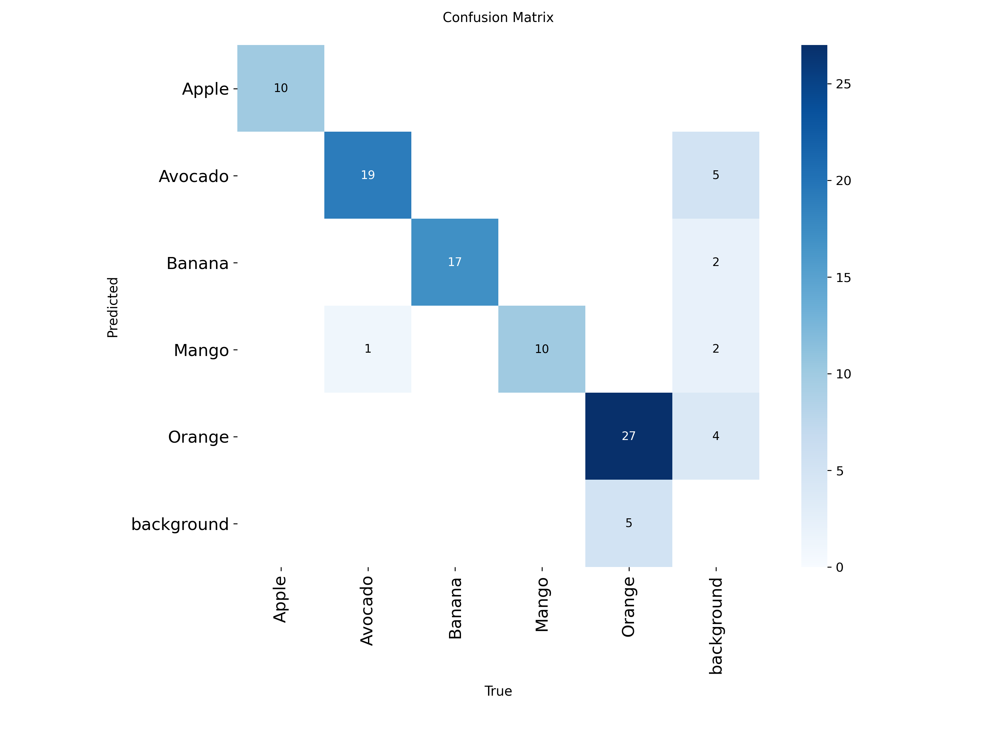

In [30]:
display(
    Image(
        filename=str(metrics.save_dir / "confusion_matrix.png")
    )
)

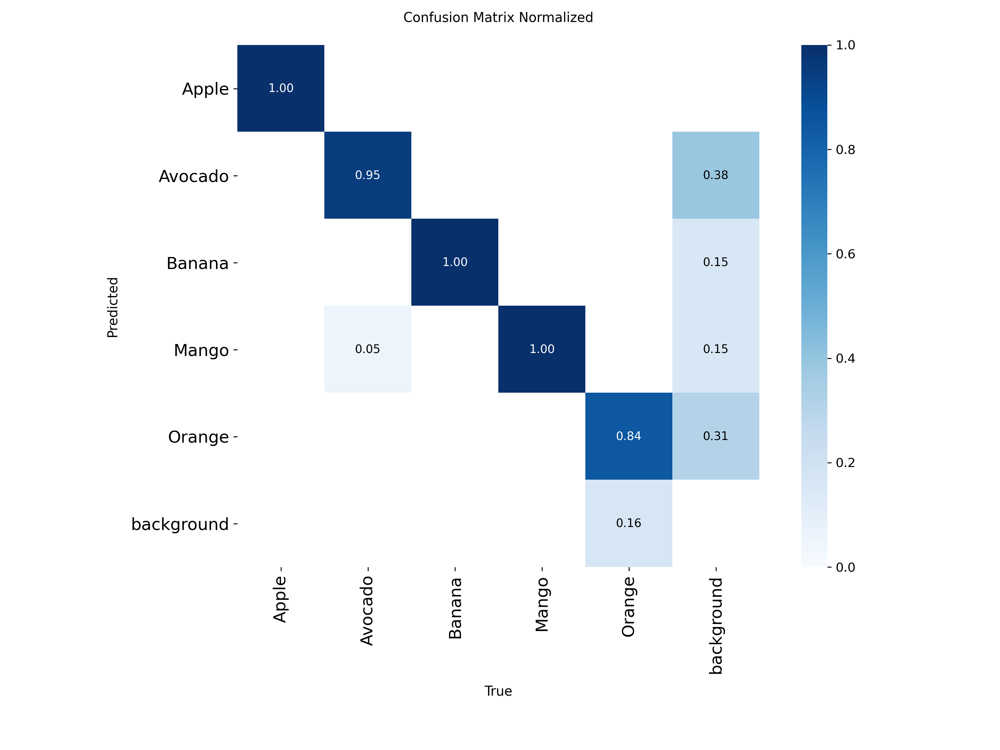

In [31]:
display(
    Image(
        filename="/content/runs/detect/val/confusion_matrix_normalized.png"
    )
)

In [33]:
from ultralytics import YOLO
import os

model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

# Using an existing image in the directory
image_path = "/content/apples-1296x728-header.webp"

if os.path.exists(image_path):
    for threshold in [0.25, 0.40, 0.50, 0.60]:
        results = model.predict(
            source=image_path,
            conf=threshold,
            save=False,
            verbose=False
        )

        print(f"\nConfidence threshold: {threshold}")

        for box in results[0].boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            print(
                f"{model.names[class_id]}: "
                f"{confidence:.3f}"
            )
else:
    print(f"Please make sure the file exists at {image_path}")


Confidence threshold: 0.25
Mango: 0.604
Mango: 0.273

Confidence threshold: 0.4
Mango: 0.604

Confidence threshold: 0.5
Mango: 0.604

Confidence threshold: 0.6
Mango: 0.604


In [35]:
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import os

# Load your trained model
model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

# Pointing to an existing image in the directory
image_path = "/content/apples-1296x728-header.webp"

# Check image exists
if not os.path.exists(image_path):
    raise FileNotFoundError(f"Image not found: {image_path}")

print("Model loaded successfully!")
print("Classes:", model.names)

Model loaded successfully!
Classes: {0: 'Apple', 1: 'Avocado', 2: 'Banana', 3: 'Mango', 4: 'Orange'}


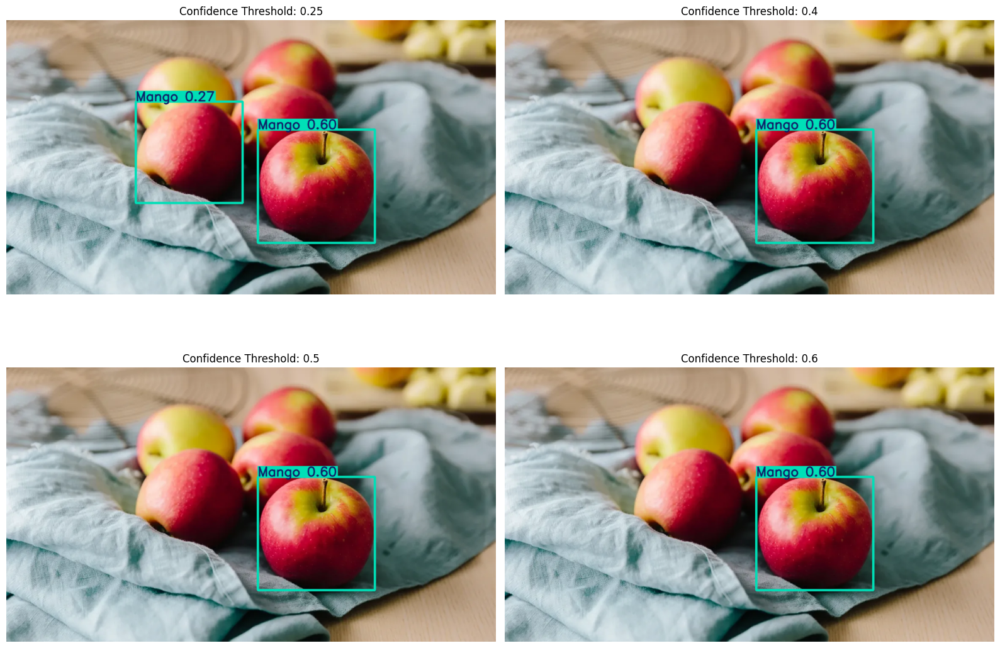

In [36]:
confidence_thresholds = [0.25, 0.40, 0.50, 0.60]

results_data = []

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, threshold in enumerate(confidence_thresholds):

    results = model.predict(
        source=image_path,
        conf=threshold,
        save=False,
        verbose=False
    )

    result = results[0]

    # Annotated image
    annotated_image = result.plot()
    annotated_image = annotated_image[:, :, ::-1]

    axes[i].imshow(annotated_image)
    axes[i].set_title(f"Confidence Threshold: {threshold}")
    axes[i].axis("off")

    # Collect detections
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        results_data.append({
            "Threshold": threshold,
            "Class": model.names[class_id],
            "Confidence": round(confidence, 4)
        })

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

df = pd.DataFrame(results_data)

if not df.empty:
    print("Detection Comparison:")
    display(df)

    print("\nTotal detections per threshold:")

    display(
        df.groupby("Threshold")
        .size()
        .reset_index(name="Total Detections")
    )
else:
    print("No objects detected at any tested threshold.")

Detection Comparison:


,Threshold,Class,Confidence
0,0.25,Mango,0.6037
1,0.25,Mango,0.2731
2,0.40,Mango,0.6037
3,0.50,Mango,0.6037
4,0.60,Mango,0.6037



Total detections per threshold:


,Threshold,Total Detections
0,0.25,2
1,0.40,1
2,0.50,1
3,0.60,1


In [38]:
results = model.predict(
    source=image_path,
    conf=0.001,
    save=False,
    verbose=False
)

result = results[0]

for box in result.boxes:
    print("\nDetection:")

    print("Predicted class:", model.names[int(box.cls[0])])
    print("Confidence:", float(box.conf[0]))

    print("Bounding box:", box.xyxy[0].tolist())


Detection:
Predicted class: Mango
Confidence: 0.6036849617958069
Bounding box: [593.2543334960938, 259.2681579589844, 869.6947021484375, 526.3511352539062]

Detection:
Predicted class: Mango
Confidence: 0.2730588912963867
Bounding box: [305.99420166015625, 193.51742553710938, 557.8865966796875, 432.5875244140625]

Detection:
Predicted class: Orange
Confidence: 0.1175905391573906
Bounding box: [309.44512939453125, 82.98582458496094, 536.8944091796875, 245.66146850585938]

Detection:
Predicted class: Orange
Confidence: 0.009785890579223633
Bounding box: [796.4007568359375, 0.0, 975.14501953125, 44.85792541503906]

Detection:
Predicted class: Mango
Confidence: 0.002860165433958173
Bounding box: [533.1846923828125, 150.1483612060547, 780.2041625976562, 316.68536376953125]

Detection:
Predicted class: Orange
Confidence: 0.0015397310489788651
Bounding box: [557.4033813476562, 39.53702163696289, 776.1456909179688, 180.20870971679688]



Actual class: Apple
Predicted: Apple | Confidence: 0.855

Actual class: Avocado
Predicted: Avocado | Confidence: 0.860

Actual class: Banana
Predicted: Banana | Confidence: 0.846

Actual class: Mango
Predicted: Mango | Confidence: 0.874
Predicted: Mango | Confidence: 0.736
Predicted: Mango | Confidence: 0.266

Actual class: Orange
Predicted: Orange | Confidence: 0.945
Predicted: Orange | Confidence: 0.927

Actual class: fruits_1
Predicted: Orange | Confidence: 0.740
Predicted: Banana | Confidence: 0.707
Predicted: Orange | Confidence: 0.254

Actual class: fruits
Predicted: Mango | Confidence: 0.461
Predicted: Mango | Confidence: 0.453
Predicted: Orange | Confidence: 0.410
Predicted: Mango | Confidence: 0.264


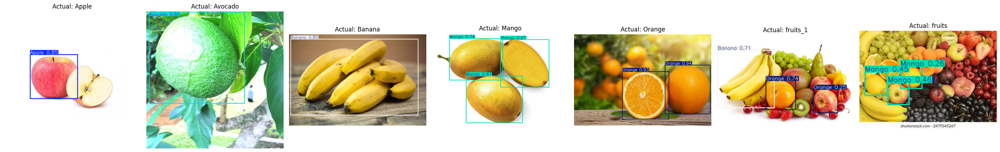

In [46]:
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import os

model = YOLO(
    "/content/runs/detect/fruit_detection/weights/best.pt"
)

# Updated dictionary keys to ensure all unique test images are preserved
test_images = {
    "Apple": "/content/apple.jpeg",
    "Avocado": "/content/fruit_dataset/valid/images/Alpukat-Bagus-14-_jpg.rf.4f5ffa1591395f729d958c5efb11c3d8.jpg",
    "Banana": "/content/banana.jpeg",
    "Mango": "/content/mango.jpeg",
    "Orange": "/content/orange.jpeg",
    "fruits_1": "/content/fruits1.jpeg",
    "fruits": "/content/fruits2.jpeg"
}

# We now have 7 images to plot side-by-side
fig, axes = plt.subplots(1, 7, figsize=(28, 6))

for i, (actual_class, image_path) in enumerate(test_images.items()):
    if not os.path.exists(image_path):
        print(f"Missing image: {image_path}")
        continue

    results = model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    annotated = result.plot()
    annotated = annotated[:, :, ::-1]

    axes[i].imshow(annotated)
    axes[i].set_title(f"Actual: {actual_class}")
    axes[i].axis("off")

    print(f"\nActual class: {actual_class}")
    if len(result.boxes) == 0:
        print("No detections")
    else:
        for box in result.boxes:
            predicted = model.names[int(box.cls[0])]
            confidence = float(box.conf[0])
            print(
                f"Predicted: {predicted} | "
                f"Confidence: {confidence:.3f}"
            )

plt.tight_layout()
plt.show()